### **Model Training** : Customer Wholeshale

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('../data/wholesale_customers_cleaned.csv')

In [3]:
df.head()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


In [4]:
# select feature x
x = df

In [5]:
x.head()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


In [6]:
# Reduce right skewed data
n_log = np.log1p(x)

In [7]:
# feature scaling
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_scaled = scaler.fit_transform(n_log)


In [8]:
from sklearn.decomposition import PCA
pca=PCA(n_components=2)
pca_scaled=pca.fit_transform(x_scaled)

In [9]:
# choose no. of clusters using elbow method
from sklearn.cluster import KMeans

wcss = []
for k in range(1,11):
    model = KMeans(n_clusters=k, init="k-means++", random_state=0)
    model.fit(pca_scaled)
    wcss.append(model.inertia_)


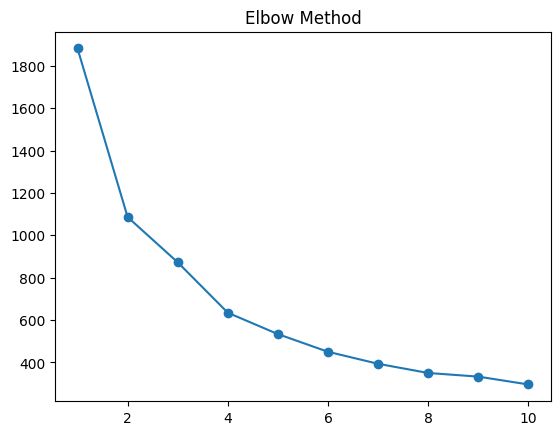

In [10]:
plt.plot(range(1,11),wcss,marker='o')
plt.title('Elbow Method')
plt.show()

In [11]:
# Easy way to find
from kneed import KneeLocator
kl=KneeLocator(range(1,11),wcss,curve="convex",direction="decreasing")
kl.elbow

np.int64(4)

In [12]:
# Train the model
from sklearn.cluster import KMeans

model = KMeans(n_clusters=kl.elbow,init="k-means++",random_state=0)
clusters = model.fit_predict(pca_scaled)


In [13]:
# add cluster labels
df["Cluster"] = clusters
df.head()


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Cluster
0,12669,9656,7561,214,2674,1338,1
1,7057,9810,9568,1762,3293,1776,1
2,6353,8808,7684,2405,3516,7844,1
3,13265,1196,4221,6404,507,1788,0
4,22615,5410,7198,3915,1777,5185,1


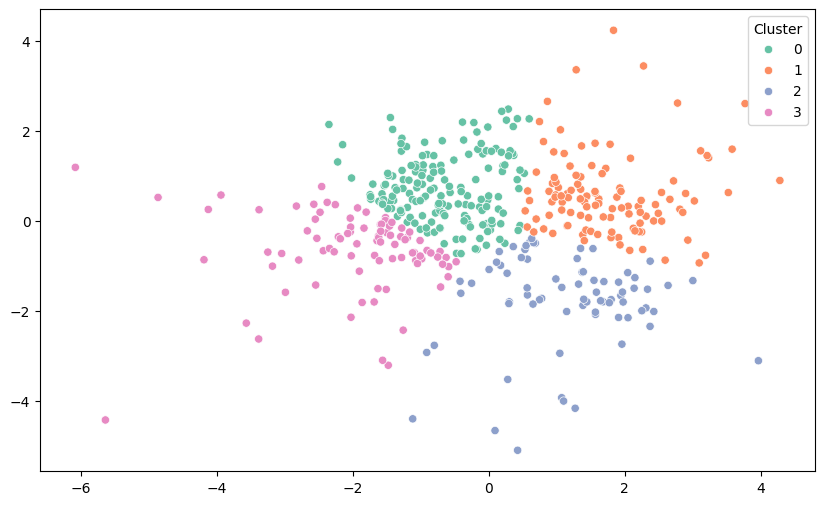

In [14]:
# plot the clusters
plt.figure(figsize=(10,6))
sns.scatterplot(x=pca_scaled[:,0],y=pca_scaled[:,1],hue=df["Cluster"],palette="Set2")
plt.show()

In [22]:
from sklearn.metrics import silhouette_score

print("Inertia:", model.inertia_)
print("Silhouette Score:", silhouette_score(x_scaled, clusters))

Inertia: 1086.052206245044
Silhouette Score: 0.2903284869973543


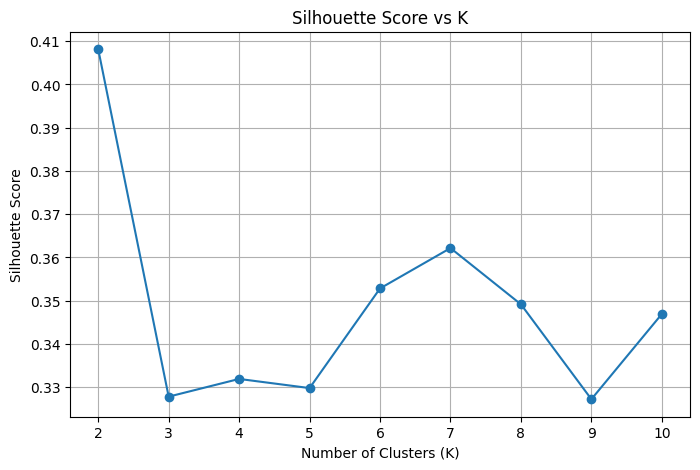

In [16]:
silhouette_scores = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        init="k-means++"
    )
    labels = model.fit_predict(pca_scaled)
    score = silhouette_score(pca_scaled, labels)
    silhouette_scores.append(score)

# Plot
plt.figure(figsize=(8, 5))
plt.plot(
    range(2, 11),
    silhouette_scores,
    marker='o'
)
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score vs K")
plt.grid()
plt.show()

___

In [17]:
# according to silhouette Score the score is high on k = 2 so give the priority to Silhouette Score 
model = KMeans(n_clusters=2, init="k-means++", random_state=42)
clusters = model.fit_predict(pca_scaled)

In [18]:
df['Cluster'] = clusters
df.head()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Cluster
0,12669,9656,7561,214,2674,1338,0
1,7057,9810,9568,1762,3293,1776,0
2,6353,8808,7684,2405,3516,7844,0
3,13265,1196,4221,6404,507,1788,1
4,22615,5410,7198,3915,1777,5185,0


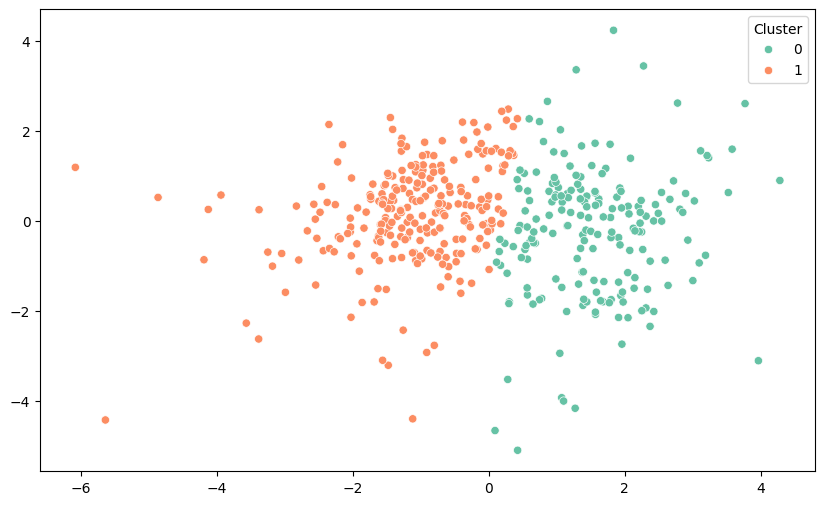

In [19]:
plt.figure(figsize=(10,6))
sns.scatterplot(x=pca_scaled[:,0],y = pca_scaled[:,1],hue=df["Cluster"],palette="Set2")
plt.show()

In [20]:
from sklearn.metrics import silhouette_score

print(f"Silhouette Score : {silhouette_score(pca_scaled,clusters)}")

Silhouette Score : 0.40815681314927427


___